<a href="https://colab.research.google.com/github/jana-i/f1-project/blob/main/F1_Data_Analysis%26Race_Predictions.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sb

%matplotlib inline

In [ ]:
from os import path
results = pd.read_csv("/content/drive/MyDrive/f1_datasets/results.csv")
races = pd.read_csv("/content/drive/MyDrive/f1_datasets/races.csv")
drivers = pd.read_csv("/content/drive/MyDrive/f1_datasets/drivers.csv")
constructurs = pd.read_csv("/content/drive/MyDrive/f1_datasets/constructors.csv")

In [ ]:
#merge all the datasets
df = pd.merge(results,races[['raceId','year','name','round']],on='raceId', how='left')
df = pd.merge(df,drivers[['driverId','driverRef','nationality']], on='driverId', how='left')
df = pd.merge(df,constructurs[['constructorId','name','nationality']], on='constructorId', how='left')

In [ ]:
df.columns

Index(['resultId', 'raceId', 'driverId', 'constructorId', 'number', 'grid',
       'position', 'positionText', 'positionOrder', 'points', 'laps', 'time',
       'milliseconds', 'fastestLap', 'rank', 'fastestLapTime',
       'fastestLapSpeed', 'statusId', 'year', 'name_x', 'round', 'driverRef',
       'nationality_x', 'name_y', 'nationality_y'],
      dtype='object')

In [ ]:
#drop some columns (unnecessary)
df.drop(['number','position','positionText','laps','fastestLap','statusId','raceId','driverId','constructorId','resultId'], axis=1,inplace=True)

In [ ]:
#rename some of the columns
df.rename(columns={'rank':'fastes_lap_rank','name_x':'gp_name','nationality_x':'driver_nationality','name_y':'constructor_name','nationality_y':'constructor_nationality',
                   'driverRef':'driver'},inplace=True)

In [ ]:
df.columns

Index(['grid', 'positionOrder', 'points', 'time', 'milliseconds',
       'fastes_lap_rank', 'fastestLapTime', 'fastestLapSpeed', 'year',
       'gp_name', 'round', 'driver', 'driver_nationality', 'constructor_name',
       'constructor_nationality'],
      dtype='object')

In [ ]:
#rearrange columns
df = df[['year','gp_name','round','driver','constructor_name','grid','positionOrder','points','time','milliseconds',
         'fastes_lap_rank','fastestLapTime','fastestLapSpeed','driver_nationality','constructor_nationality']]

In [ ]:
df.head()

,year,gp_name,round,driver,constructor_name,grid,positionOrder,points,time,milliseconds,fastes_lap_rank,fastestLapTime,fastestLapSpeed,driver_nationality,constructor_nationality
0,2008,Australian Grand Prix,1,hamilton,McLaren,1,1,10.0,1:34:50.616,5690616,2,1:27.452,218.300,British,British
1,2008,Australian Grand Prix,1,heidfeld,BMW Sauber,5,2,8.0,+5.478,5696094,3,1:27.739,217.586,German,German
2,2008,Australian Grand Prix,1,rosberg,Williams,7,3,6.0,+8.163,5698779,5,1:28.090,216.719,German,British
3,2008,Australian Grand Prix,1,alonso,Renault,11,4,5.0,+17.181,5707797,7,1:28.603,215.464,Spanish,French
4,2008,Australian Grand Prix,1,kovalainen,McLaren,3,5,4.0,+18.014,5708630,1,1:27.418,218.385,Finnish,British


In [ ]:
#drop 2019 race because it is incomplite
df = df[df['year']!=2019]

In [ ]:
#sort the values
df = df.sort_values(by=['year','round','positionOrder'],ascending=[False,True,True])

In [ ]:
df.head()

,year,gp_name,round,driver,constructor_name,grid,positionOrder,points,time,milliseconds,fastes_lap_rank,fastestLapTime,fastestLapSpeed,driver_nationality,constructor_nationality
26280,2024,Bahrain Grand Prix,1,max_verstappen,Red Bull,1,1,26.0,1:31:44.742,5504742,1,1:32.608,210.383,Dutch,Austrian
26281,2024,Bahrain Grand Prix,1,perez,Red Bull,5,2,18.0,+22.457,5527199,4,1:34.364,206.468,Mexican,Austrian
26282,2024,Bahrain Grand Prix,1,sainz,Ferrari,4,3,15.0,+25.110,5529852,6,1:34.507,206.156,Spanish,Italian
26283,2024,Bahrain Grand Prix,1,leclerc,Ferrari,2,4,12.0,+39.669,5544411,2,1:34.090,207.069,Monegasque,Italian
26284,2024,Bahrain Grand Prix,1,russell,Mercedes,3,5,10.0,+46.788,5551530,12,1:35.065,204.946,British,German


In [ ]:
#replace \N values in the time col
df.replace({
    'time': '\\N',
    'milliseconds': '\\N',
    'fastes_lap_rank': '\\N',
    'fastestLapTime': '\\N',
    'fastestLapSpeed': '\\N'
}, np.nan, inplace=True)

In [ ]:
#change datatypes

df.fastestLapSpeed = df.fastestLapSpeed.astype('float')
df.fastes_lap_rank = df.fastes_lap_rank.astype('float')
df.milliseconds = df.milliseconds.astype('float')

In [ ]:
#reset index
df.reset_index(drop=True,inplace=True)

In [ ]:
#shape
df.shape

(26339, 15)

In [ ]:
#info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26339 entries, 0 to 26338
Data columns (total 15 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   year                     26339 non-null  int64  
 1   gp_name                  26339 non-null  object 
 2   round                    26339 non-null  int64  
 3   driver                   26339 non-null  object 
 4   constructor_name         26339 non-null  object 
 5   grid                     26339 non-null  int64  
 6   positionOrder            26339 non-null  int64  
 7   points                   26339 non-null  float64
 8   time                     7484 non-null   object 
 9   milliseconds             7484 non-null   float64
 10  fastes_lap_rank          8090 non-null   float64
 11  fastestLapTime           7836 non-null   object 
 12  fastestLapSpeed          7836 non-null   float64
 13  driver_nationality       26339 non-null  object 
 14  constructor_nationalit

In [ ]:
#head
df.head()

,year,gp_name,round,driver,constructor_name,grid,positionOrder,points,time,milliseconds,fastes_lap_rank,fastestLapTime,fastestLapSpeed,driver_nationality,constructor_nationality
0,2024,Bahrain Grand Prix,1,max_verstappen,Red Bull,1,1,26.0,1:31:44.742,5504742.0,1.0,1:32.608,210.383,Dutch,Austrian
1,2024,Bahrain Grand Prix,1,perez,Red Bull,5,2,18.0,+22.457,5527199.0,4.0,1:34.364,206.468,Mexican,Austrian
2,2024,Bahrain Grand Prix,1,sainz,Ferrari,4,3,15.0,+25.110,5529852.0,6.0,1:34.507,206.156,Spanish,Italian
3,2024,Bahrain Grand Prix,1,leclerc,Ferrari,2,4,12.0,+39.669,5544411.0,2.0,1:34.090,207.069,Monegasque,Italian
4,2024,Bahrain Grand Prix,1,russell,Mercedes,3,5,10.0,+46.788,5551530.0,12.0,1:35.065,204.946,British,German


In [ ]:
sb.set_palette('Set3')
plt.rcParams['figure.figsize']=10,6

([], [])

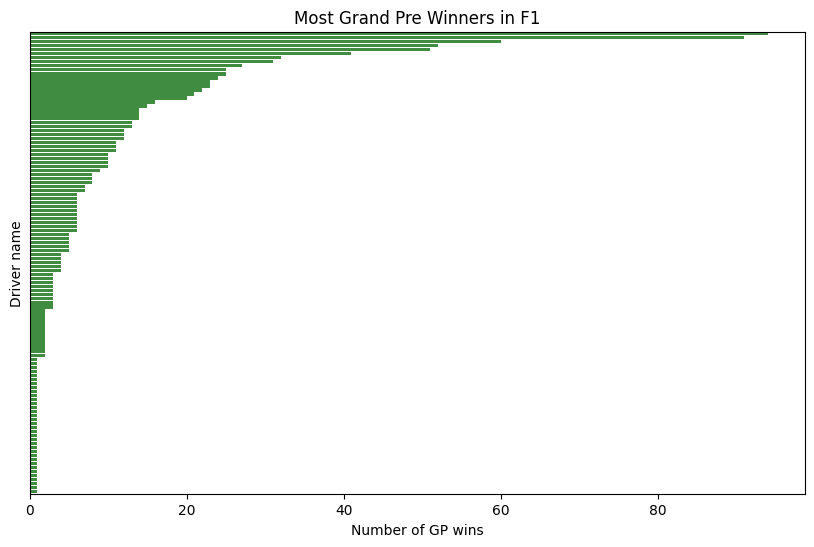

In [ ]:
#GP winners
#the driver who one the race
driver_winner = df.loc[df['positionOrder']==1].groupby('driver')['positionOrder'].count().sort_values(ascending=False).to_frame().reset_index()

#Barplot

sb.barplot(data=driver_winner, y='driver',x='positionOrder',color='green',alpha=0.8)
plt.title('Most Grand Pre Winners in F1')
plt.ylabel('Driver name')
plt.xlabel('Number of GP wins')
plt.yticks([])

In [ ]:
topDrivers = driver_winner.head(10)
print(topDrivers)

               driver  positionOrder
0            hamilton             94
1  michael_schumacher             91
2      max_verstappen             60
3              vettel             52
4               prost             51
5               senna             41
6              alonso             32
7             mansell             31
8             stewart             27
9               lauda             25


Text(0.5, 0, 'Number of wins')

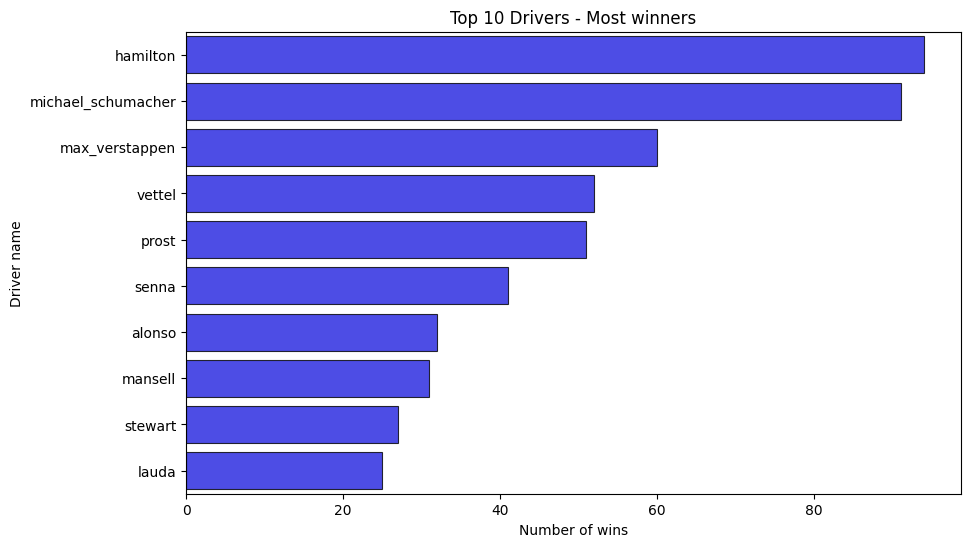

In [ ]:
#top 10 drivers plot

sb.barplot(data = topDrivers, y='driver', x='positionOrder',color='blue',alpha=0.8,linewidth=.8,edgecolor='black')
plt.title('Top 10 Drivers - Most winners')
plt.ylabel('Driver name')
plt.xlabel('Number of wins')

([], [])

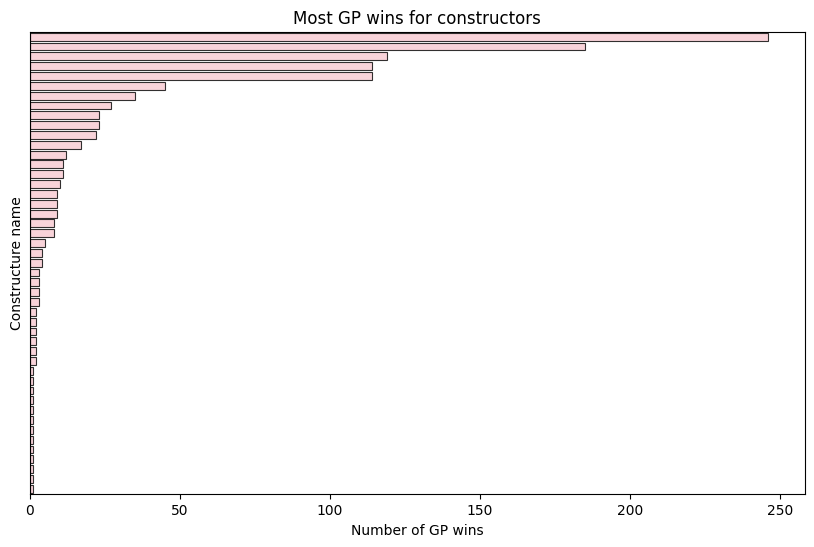

In [ ]:
#GP constructor winners
constructor_winner = df.loc[df['positionOrder']==1].groupby('constructor_name')['positionOrder'].count().sort_values(ascending=False).to_frame().reset_index()

#barplot
sb.barplot(data = constructor_winner, y='constructor_name',x='positionOrder',
           color='pink',alpha=0.8,linewidth=.8,edgecolor='black')
plt.title('Most GP wins for constructors')
plt.ylabel('Constructure name')
plt.xlabel('Number of GP wins')
plt.yticks([])

In [ ]:
topConstructors = constructor_winner.head(10)
print(topConstructors)

  constructor_name  positionOrder
0          Ferrari            246
1          McLaren            185
2         Red Bull            119
3         Mercedes            114
4         Williams            114
5       Team Lotus             45
6          Renault             35
7         Benetton             27
8          Tyrrell             23
9          Brabham             23


Text(0.5, 0, 'Most GP wins for constructor')

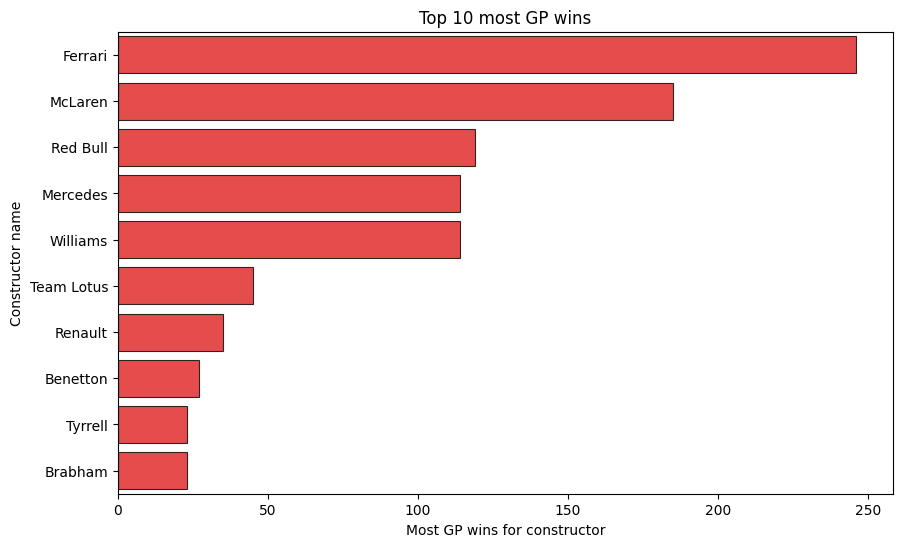

In [ ]:
#barplot
sb.barplot(data=topConstructors, y='constructor_name', x='positionOrder',color='red',alpha=0.8,linewidth=.8,edgecolor='black')
plt.title('Top 10 most GP wins')
plt.ylabel('Constructor name')
plt.xlabel('Most GP wins for constructor')

Text(0.5, 0, 'Starting position')

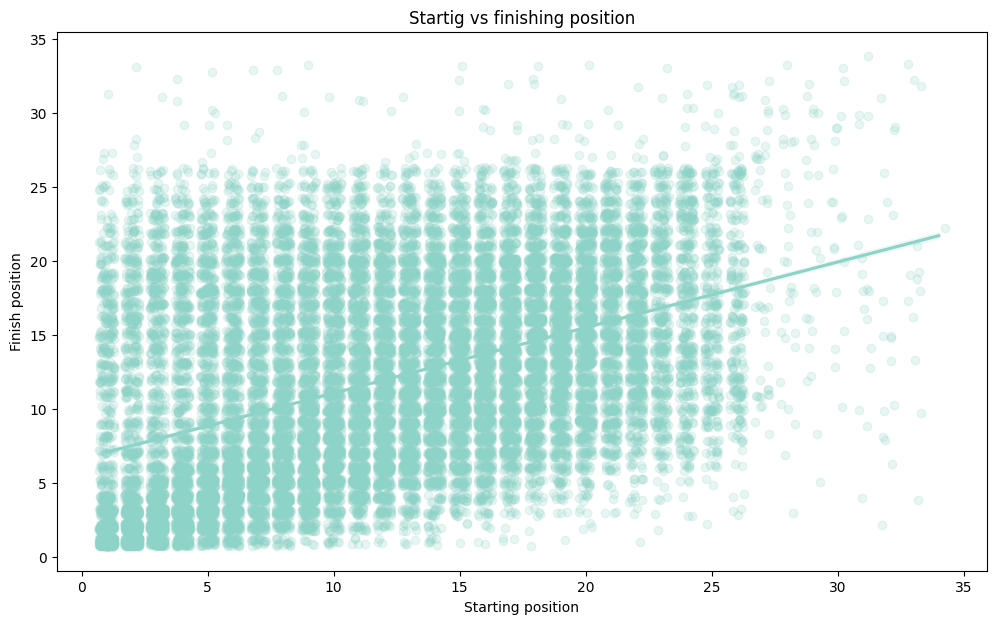

In [ ]:
#regression plot that will show two variables starting and finish position vairy

df_no_zero = df[df['grid']!=0]

plt.figure(figsize = [12,7])
sb.regplot(data = df_no_zero,x='grid', y='positionOrder', x_jitter=0.3, y_jitter=0.3, scatter_kws={'alpha':1/5})
plt.title('Startig vs finishing position')
plt.ylabel('Finish position')
plt.xlabel('Starting position')

Text(0.5, 0.98, 'Average speed among all teams during the fastest lap at individual GP')

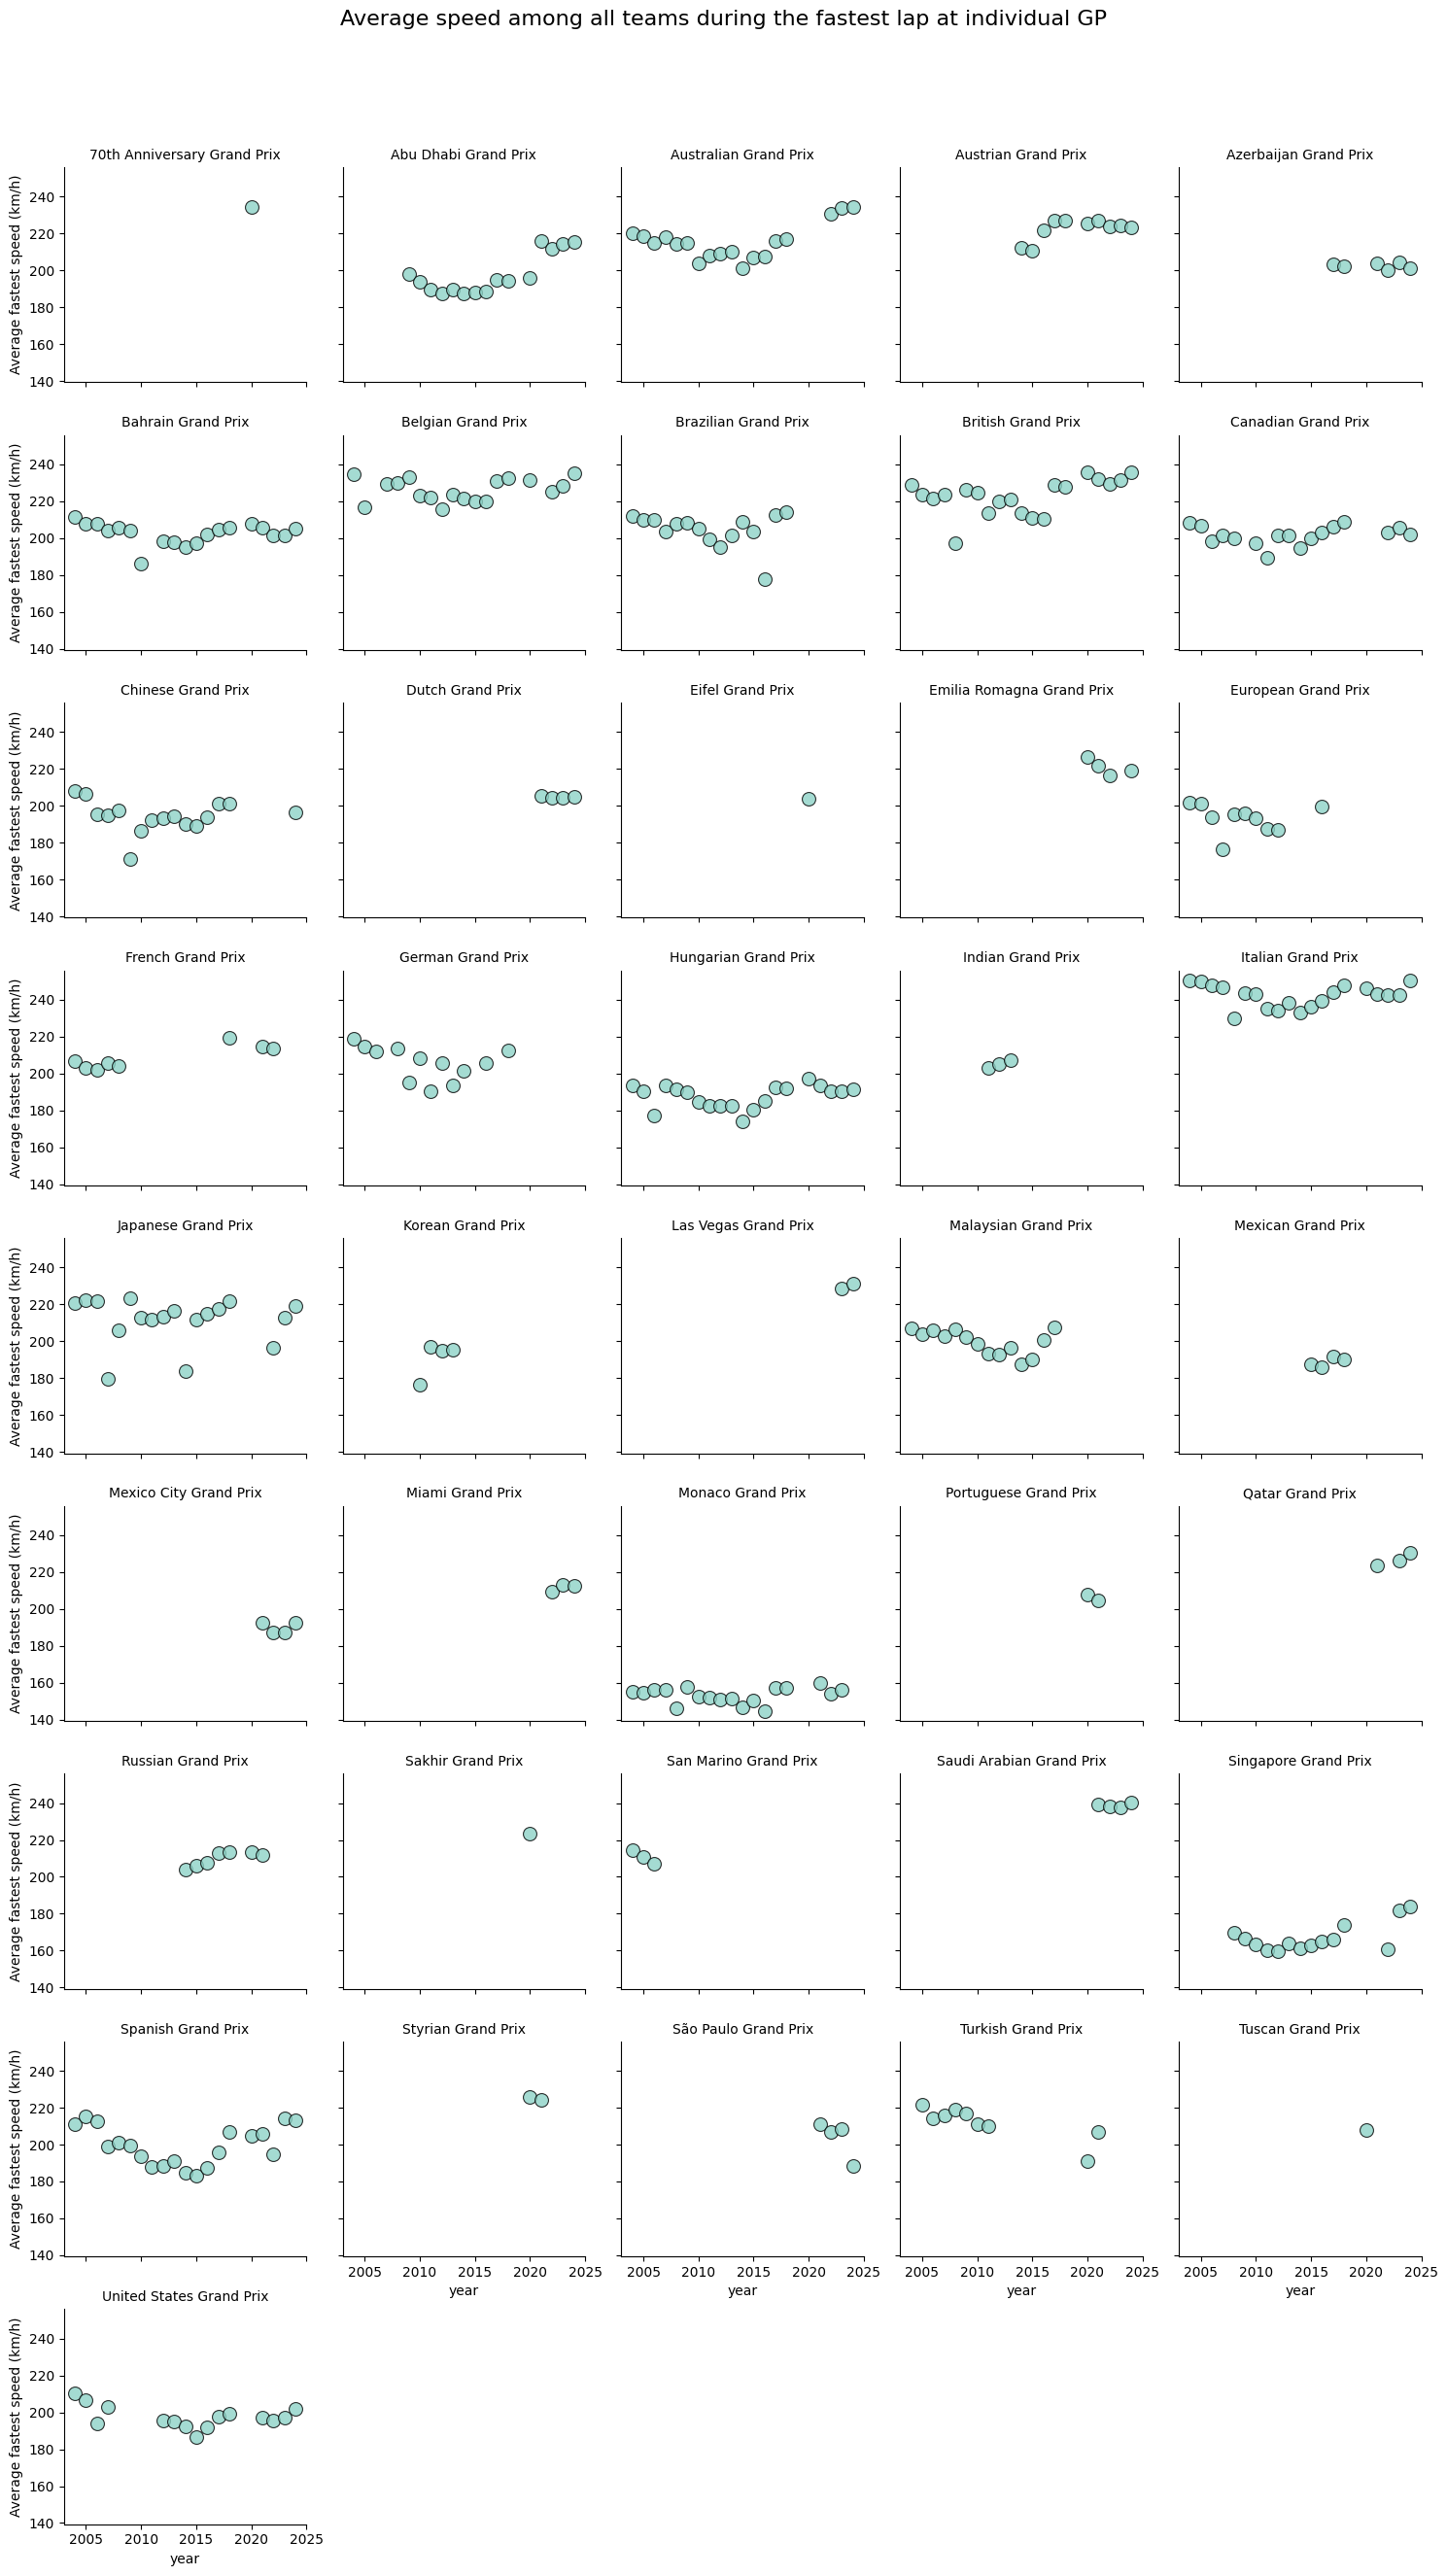

In [ ]:
#create new data frame for season onwards 2004

df_speed = df[df['year']>=2004]
df_group_speed = df_speed.groupby(['gp_name','year'])['fastestLapSpeed'].mean().to_frame().reset_index()

#create a facegrid

g = sb.FacetGrid(data = df_group_speed, col='gp_name',col_wrap=5)
g.map(plt.scatter, 'year', 'fastestLapSpeed', alpha=0.8, linewidth=.8, edgecolor='black', s=100)
g.set_titles("{col_name}")
g.set_xlabels('year')
g.set_ylabels('Average fastest speed (km/h)')
plt.subplots_adjust(top=0.92)
g.fig.suptitle('Average speed among all teams during the fastest lap at individual GP', fontsize=16)

In [1]:
pip install fastf1

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 151.2/151.2 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.4/61.4 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 164.8/164.8 kB 6.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 46.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.4/69.4 kB 4.3 MB/s eta 0:00:00
  Attempting uninstall: websockets
    Found existing installation: websockets 15.0.1
    Uninstalling websockets-15.0.1:
      Successfully uninstalled websockets-15.0.1
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dataproc-spark-connect 0.7.5 requires websockets>=14.0, but you have websockets 13.1 which is incompatible.


In [2]:
import os
import fastf1
import pandas as pd
import numpy as np
import seaborn as sb
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error

In [3]:
cache_folder = 'cache_folder'
if not os.path.exists(cache_folder):
  os.makedirs(cache_folder)

In [4]:
fastf1.Cache.enable_cache("cache_folder")
sessions_2024_miami = fastf1.get_session(2024,'Miami','R')
sessions_2024_miami.load()

core           INFO 	Loading data for Miami Grand Prix - Race [v3.5.3]
INFO:fastf1.fastf1.core:Loading data for Miami Grand Prix - Race [v3.5.3]
req            INFO 	No cached data found for session_info. Loading data...
INFO:fastf1.fastf1.req:No cached data found for session_info. Loading data...
_api           INFO 	Fetching session info data...
INFO:fastf1.api:Fetching session info data...
req            INFO 	Data has been written to cache!
INFO:fastf1.fastf1.req:Data has been written to cache!
req            INFO 	No cached data found for driver_info. Loading data...
INFO:fastf1.fastf1.req:No cached data found for driver_info. Loading data...
_api           INFO 	Fetching driver list...
INFO:fastf1.api:Fetching driver list...
req            INFO 	Data has been written to cache!
INFO:fastf1.fastf1.req:Data has been written to cache!
req            INFO 	No cached data found for session_status_data. Loading data...
INFO:fastf1.fastf1.req:No cached data found for session_status_data.

In [5]:
#ги земам годините, која трака и каков тип на сесија ми и потребно а тоа е официјалната трка
years = [2022,2023,2024]
track = ['Miami']
session_type = 'R'

In [6]:
all_laps = []

for year in years:
  try:
    session = fastf1.get_session(year,track,session_type)
    session.load()
    laps = session.laps.copy()

    all_laps.append(laps)

  except Exception as e:
    print(f"Could not load {track} {session_type} for {year}: {e}")

Could not load ['Miami'] R for 2022: ('Lengths must match to compare', (22,), (1,))
Could not load ['Miami'] R for 2023: ('Lengths must match to compare', (22,), (1,))
Could not load ['Miami'] R for 2024: ('Lengths must match to compare', (24,), (1,))


In [7]:
from fastf1 import get_event_schedule

def inspect_session(year):
  try:
    schedule = get_event_schedule(year)
    miami_event = schedule[schedule["EventName"].str.contains("Miami",case=False)].iloc[0]

    session = fastf1.get_session(year, miami_event['EventName'], "R")
    session.load()
    laps = session.laps.copy()

    laps["Year"] = year

    return laps
  except Exception as e:
        print(f" Could not load Miami Race for {year}: {e}")
        return None

In [8]:
all_laps = []

for year in years:
  laps = inspect_session(year)
  if laps is not None:
    all_laps.append(laps)

core           INFO 	Loading data for Miami Grand Prix - Race [v3.5.3]
INFO:fastf1.fastf1.core:Loading data for Miami Grand Prix - Race [v3.5.3]
req            INFO 	No cached data found for session_info. Loading data...
INFO:fastf1.fastf1.req:No cached data found for session_info. Loading data...
_api           INFO 	Fetching session info data...
INFO:fastf1.api:Fetching session info data...
DEBUG:fastf1.api:Falling back to livetiming mirror (https://livetiming-mirror.fastf1.dev)
req            INFO 	Data has been written to cache!
INFO:fastf1.fastf1.req:Data has been written to cache!
req            INFO 	No cached data found for driver_info. Loading data...
INFO:fastf1.fastf1.req:No cached data found for driver_info. Loading data...
_api           INFO 	Fetching driver list...
INFO:fastf1.api:Fetching driver list...
DEBUG:fastf1.api:Falling back to livetiming mirror (https://livetiming-mirror.fastf1.dev)
req            INFO 	Data has been written to cache!
INFO:fastf1.fastf1.req:Dat

In [9]:
#да ги комбинирам сите во еден DataFrame
combined_laps = pd.concat(all_laps, ignore_index=True)

In [10]:
print(combined_laps.shape)

(3306, 32)


In [11]:
combined_laps.head()

,Time,Driver,DriverNumber,LapTime,LapNumber,Stint,PitOutTime,PitInTime,Sector1Time,Sector2Time,...,Team,LapStartTime,LapStartDate,TrackStatus,Position,Deleted,DeletedReason,FastF1Generated,IsAccurate,Year
0,0 days 01:03:53.373000,VER,1,0 days 00:01:37.528000,1.0,1.0,NaT,NaT,NaT,0 days 00:00:35.848000,...,Red Bull Racing,0 days 01:02:16.435000,2022-05-08 19:33:16.443,1,2.0,False,,False,False,2022
1,0 days 01:05:27.915000,VER,1,0 days 00:01:34.542000,2.0,1.0,NaT,NaT,0 days 00:00:32.267000,0 days 00:00:35.970000,...,Red Bull Racing,0 days 01:03:53.373000,2022-05-08 19:34:53.381,1,2.0,False,,False,True,2022
2,0 days 01:07:02.465000,VER,1,0 days 00:01:34.550000,3.0,1.0,NaT,NaT,0 days 00:00:32.182000,0 days 00:00:36.062000,...,Red Bull Racing,0 days 01:05:27.915000,2022-05-08 19:36:27.923,1,2.0,False,,False,True,2022
3,0 days 01:08:36.752000,VER,1,0 days 00:01:34.287000,4.0,1.0,NaT,NaT,0 days 00:00:32.092000,0 days 00:00:35.968000,...,Red Bull Racing,0 days 01:07:02.465000,2022-05-08 19:38:02.473,1,2.0,False,,False,True,2022
4,0 days 01:10:11.072000,VER,1,0 days 00:01:34.320000,5.0,1.0,NaT,NaT,0 days 00:00:32.028000,0 days 00:00:35.942000,...,Red Bull Racing,0 days 01:08:36.752000,2022-05-08 19:39:36.760,1,2.0,False,,False,True,2022


In [12]:
print(combined_laps.columns)

Index(['Time', 'Driver', 'DriverNumber', 'LapTime', 'LapNumber', 'Stint',
       'PitOutTime', 'PitInTime', 'Sector1Time', 'Sector2Time', 'Sector3Time',
       'Sector1SessionTime', 'Sector2SessionTime', 'Sector3SessionTime',
       'SpeedI1', 'SpeedI2', 'SpeedFL', 'SpeedST', 'IsPersonalBest',
       'Compound', 'TyreLife', 'FreshTyre', 'Team', 'LapStartTime',
       'LapStartDate', 'TrackStatus', 'Position', 'Deleted', 'DeletedReason',
       'FastF1Generated', 'IsAccurate', 'Year'],
      dtype='object')


In [13]:
#ги отгнувам тие кои имаат null вредност (само на тие кои имаат извршено одреден lap)
combined_laps = combined_laps[combined_laps['LapTime'].notna()]

In [14]:
combined_laps

,Time,Driver,DriverNumber,LapTime,LapNumber,Stint,PitOutTime,PitInTime,Sector1Time,Sector2Time,...,Team,LapStartTime,LapStartDate,TrackStatus,Position,Deleted,DeletedReason,FastF1Generated,IsAccurate,Year
0,0 days 01:03:53.373000,VER,1,0 days 00:01:37.528000,1.0,1.0,NaT,NaT,NaT,0 days 00:00:35.848000,...,Red Bull Racing,0 days 01:02:16.435000,2022-05-08 19:33:16.443,1,2.0,False,,False,False,2022
1,0 days 01:05:27.915000,VER,1,0 days 00:01:34.542000,2.0,1.0,NaT,NaT,0 days 00:00:32.267000,0 days 00:00:35.970000,...,Red Bull Racing,0 days 01:03:53.373000,2022-05-08 19:34:53.381,1,2.0,False,,False,True,2022
2,0 days 01:07:02.465000,VER,1,0 days 00:01:34.550000,3.0,1.0,NaT,NaT,0 days 00:00:32.182000,0 days 00:00:36.062000,...,Red Bull Racing,0 days 01:05:27.915000,2022-05-08 19:36:27.923,1,2.0,False,,False,True,2022
3,0 days 01:08:36.752000,VER,1,0 days 00:01:34.287000,4.0,1.0,NaT,NaT,0 days 00:00:32.092000,0 days 00:00:35.968000,...,Red Bull Racing,0 days 01:07:02.465000,2022-05-08 19:38:02.473,1,2.0,False,,False,True,2022
4,0 days 01:10:11.072000,VER,1,0 days 00:01:34.320000,5.0,1.0,NaT,NaT,0 days 00:00:32.028000,0 days 00:00:35.942000,...,Red Bull Racing,0 days 01:08:36.752000,2022-05-08 19:39:36.760,1,2.0,False,,False,True,2022
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3301,0 days 02:21:15.138000,PIA,81,0 days 00:01:32.610000,53.0,3.0,NaT,NaT,0 days 00:00:31.675000,0 days 00:00:35.281000,...,McLaren,0 days 02:19:42.528000,2024-05-05 21:27:23.296,1,16.0,False,,False,True,2024
3302,0 days 02:22:47.070000,PIA,81,0 days 00:01:31.932000,54.0,3.0,NaT,NaT,0 days 00:00:31.311000,0 days 00:00:35.210000,...,McLaren,0 days 02:21:15.138000,2024-05-05 21:28:55.906,1,15.0,False,,False,True,2024
3303,0 days 02:24:18.735000,PIA,81,0 days 00:01:31.665000,55.0,3.0,NaT,NaT,0 days 00:00:30.878000,0 days 00:00:35.143000,...,McLaren,0 days 02:22:47.070000,2024-05-05 21:30:27.838,1,15.0,False,,False,True,2024
3304,0 days 02:25:50.789000,PIA,81,0 days 00:01:32.054000,56.0,3.0,NaT,NaT,0 days 00:00:31.051000,0 days 00:00:35.296000,...,McLaren,0 days 02:24:18.735000,2024-05-05 21:31:59.503,1,15.0,False,,False,True,2024


In [16]:
laps_new = combined_laps[["Driver", "LapTime", "Sector1Time", "Sector2Time", "Sector3Time","Year"]].copy()
laps_new.dropna(inplace=True)

In [17]:
laps_new

,Driver,LapTime,Sector1Time,Sector2Time,Sector3Time,Year
1,VER,0 days 00:01:34.542000,0 days 00:00:32.267000,0 days 00:00:35.970000,0 days 00:00:26.305000,2022
2,VER,0 days 00:01:34.550000,0 days 00:00:32.182000,0 days 00:00:36.062000,0 days 00:00:26.306000,2022
3,VER,0 days 00:01:34.287000,0 days 00:00:32.092000,0 days 00:00:35.968000,0 days 00:00:26.227000,2022
4,VER,0 days 00:01:34.320000,0 days 00:00:32.028000,0 days 00:00:35.942000,0 days 00:00:26.350000,2022
5,VER,0 days 00:01:34.227000,0 days 00:00:31.891000,0 days 00:00:35.971000,0 days 00:00:26.365000,2022
...,...,...,...,...,...,...
3301,PIA,0 days 00:01:32.610000,0 days 00:00:31.675000,0 days 00:00:35.281000,0 days 00:00:25.654000,2024
3302,PIA,0 days 00:01:31.932000,0 days 00:00:31.311000,0 days 00:00:35.210000,0 days 00:00:25.411000,2024
3303,PIA,0 days 00:01:31.665000,0 days 00:00:30.878000,0 days 00:00:35.143000,0 days 00:00:25.644000,2024
3304,PIA,0 days 00:01:32.054000,0 days 00:00:31.051000,0 days 00:00:35.296000,0 days 00:00:25.707000,2024


In [18]:
for col in ["LapTime", "Sector1Time", "Sector2Time", "Sector3Time"]:
    laps_new[f"{col} (s)"] = laps_new[col].dt.total_seconds()

In [19]:
laps_new

,Driver,LapTime,Sector1Time,Sector2Time,Sector3Time,Year,LapTime (s),Sector1Time (s),Sector2Time (s),Sector3Time (s)
1,VER,0 days 00:01:34.542000,0 days 00:00:32.267000,0 days 00:00:35.970000,0 days 00:00:26.305000,2022,94.542,32.267,35.970,26.305
2,VER,0 days 00:01:34.550000,0 days 00:00:32.182000,0 days 00:00:36.062000,0 days 00:00:26.306000,2022,94.550,32.182,36.062,26.306
3,VER,0 days 00:01:34.287000,0 days 00:00:32.092000,0 days 00:00:35.968000,0 days 00:00:26.227000,2022,94.287,32.092,35.968,26.227
4,VER,0 days 00:01:34.320000,0 days 00:00:32.028000,0 days 00:00:35.942000,0 days 00:00:26.350000,2022,94.320,32.028,35.942,26.350
5,VER,0 days 00:01:34.227000,0 days 00:00:31.891000,0 days 00:00:35.971000,0 days 00:00:26.365000,2022,94.227,31.891,35.971,26.365
...,...,...,...,...,...,...,...,...,...,...
3301,PIA,0 days 00:01:32.610000,0 days 00:00:31.675000,0 days 00:00:35.281000,0 days 00:00:25.654000,2024,92.610,31.675,35.281,25.654
3302,PIA,0 days 00:01:31.932000,0 days 00:00:31.311000,0 days 00:00:35.210000,0 days 00:00:25.411000,2024,91.932,31.311,35.210,25.411
3303,PIA,0 days 00:01:31.665000,0 days 00:00:30.878000,0 days 00:00:35.143000,0 days 00:00:25.644000,2024,91.665,30.878,35.143,25.644
3304,PIA,0 days 00:01:32.054000,0 days 00:00:31.051000,0 days 00:00:35.296000,0 days 00:00:25.707000,2024,92.054,31.051,35.296,25.707


In [20]:
sector_times_new = laps_new.groupby("Driver")[["Sector1Time (s)", "Sector2Time (s)", "Sector3Time (s)"]].mean().reset_index()

In [21]:
sector_times_new

,Driver,Sector1Time (s),Sector2Time (s),Sector3Time (s)
0,ALB,33.063114,36.412659,26.855886
1,ALO,32.632874,36.421395,26.814725
2,BOT,32.612006,36.379283,26.825687
3,DEV,31.989964,35.403107,26.160696
4,GAS,32.709719,36.147588,26.593706
5,HAM,32.548783,36.223259,26.675440
6,HUL,32.567080,35.942884,26.320161
7,LAT,33.693148,37.032185,27.316852
8,LEC,32.261323,35.982817,26.378909
9,MAG,33.065217,36.251723,26.893096


In [22]:
fastf1.Cache.enable_cache("cache_folder")
session_2024 = fastf1.get_session(2024, "China", "R")
session_2024.load()

core           INFO 	Loading data for Chinese Grand Prix - Race [v3.5.3]
INFO:fastf1.fastf1.core:Loading data for Chinese Grand Prix - Race [v3.5.3]
req            INFO 	No cached data found for session_info. Loading data...
INFO:fastf1.fastf1.req:No cached data found for session_info. Loading data...
_api           INFO 	Fetching session info data...
INFO:fastf1.api:Fetching session info data...
req            INFO 	Data has been written to cache!
INFO:fastf1.fastf1.req:Data has been written to cache!
req            INFO 	No cached data found for driver_info. Loading data...
INFO:fastf1.fastf1.req:No cached data found for driver_info. Loading data...
_api           INFO 	Fetching driver list...
INFO:fastf1.api:Fetching driver list...
req            INFO 	Data has been written to cache!
INFO:fastf1.fastf1.req:Data has been written to cache!
req            INFO 	No cached data found for session_status_data. Loading data...
INFO:fastf1.fastf1.req:No cached data found for session_status_d

In [23]:
session_2024.laps.columns

Index(['Time', 'Driver', 'DriverNumber', 'LapTime', 'LapNumber', 'Stint',
       'PitOutTime', 'PitInTime', 'Sector1Time', 'Sector2Time', 'Sector3Time',
       'Sector1SessionTime', 'Sector2SessionTime', 'Sector3SessionTime',
       'SpeedI1', 'SpeedI2', 'SpeedFL', 'SpeedST', 'IsPersonalBest',
       'Compound', 'TyreLife', 'FreshTyre', 'Team', 'LapStartTime',
       'LapStartDate', 'TrackStatus', 'Position', 'Deleted', 'DeletedReason',
       'FastF1Generated', 'IsAccurate'],
      dtype='object')

In [24]:
laps_2024 = session_2024.laps[["Driver", "LapTime", "Sector1Time", "Sector2Time", "Sector3Time"]].copy()
laps_2024.dropna(inplace=True)

In [25]:
for col in ["LapTime", "Sector1Time", "Sector2Time", "Sector3Time"]:
    laps_2024[f"{col} (s)"] = laps_2024[col].dt.total_seconds()

In [26]:
sector_times_2024 = laps_2024.groupby("Driver")[["Sector1Time (s)", "Sector2Time (s)", "Sector3Time (s)"]].mean().reset_index()

In [27]:
sector_times_2024

,Driver,Sector1Time (s),Sector2Time (s),Sector3Time (s)
0,ALB,29.195855,32.869764,47.183400
1,ALO,28.987283,31.951038,46.439189
2,BOT,28.427278,31.032222,44.450000
3,GAS,29.548364,32.672455,47.085909
4,HAM,29.151218,32.691655,47.230545
5,HUL,28.528833,32.721778,47.186685
6,LEC,28.025712,31.970673,46.015577
7,MAG,29.049463,32.419815,47.019852
8,NOR,28.553593,32.451481,46.493556
9,OCO,29.098545,32.626400,47.483582


In [28]:
qualifying_2025 = pd.DataFrame({
    "Driver": ["Oscar Piastri", "George Russell", "Lando Norris", "Max Verstappen", "Lewis Hamilton",
               "Charles Leclerc", "Isack Hadjar", "Andrea Kimi Antonelli", "Yuki Tsunoda", "Alexander Albon",
               "Esteban Ocon", "Nico Hülkenberg", "Fernando Alonso", "Lance Stroll", "Carlos Sainz Jr.",
               "Pierre Gasly", "Oliver Bearman", "Jack Doohan", "Gabriel Bortoleto", "Liam Lawson"],
    "QualifyingTime (s)": [90.641, 90.723, 90.793, 90.817, 90.927,
                           91.021, 91.079, 91.103, 91.638, 91.706,
                           91.625, 91.632, 91.688, 91.773, 91.840,
                           91.992, 92.018, 92.092, 92.141, 92.174]
})

In [29]:
qualifying_2025

,Driver,QualifyingTime (s)
0,Oscar Piastri,90.641
1,George Russell,90.723
2,Lando Norris,90.793
3,Max Verstappen,90.817
4,Lewis Hamilton,90.927
5,Charles Leclerc,91.021
6,Isack Hadjar,91.079
7,Andrea Kimi Antonelli,91.103
8,Yuki Tsunoda,91.638
9,Alexander Albon,91.706


In [30]:
driver_mapping = {
    "Oscar Piastri": "PIA", "George Russell": "RUS", "Lando Norris": "NOR", "Max Verstappen": "VER",
    "Lewis Hamilton": "HAM", "Charles Leclerc": "LEC", "Isack Hadjar": "HAD", "Andrea Kimi Antonelli": "ANT",
    "Yuki Tsunoda": "TSU", "Alexander Albon": "ALB", "Esteban Ocon": "OCO", "Nico Hülkenberg": "HUL",
    "Fernando Alonso": "ALO", "Lance Stroll": "STR", "Carlos Sainz Jr.": "SAI", "Pierre Gasly": "GAS",
    "Oliver Bearman": "BEA", "Jack Doohan": "DOO", "Gabriel Bortoleto": "BOR", "Liam Lawson": "LAW"
}

In [31]:
qualifying_2025["DriverCode"] = qualifying_2025["Driver"].map(driver_mapping)
qualifying_2025["DriverCode"]

,DriverCode
0,PIA
1,RUS
2,NOR
3,VER
4,HAM
5,LEC
6,HAD
7,ANT
8,TSU
9,ALB


In [32]:
qualifying_2025["DriverCode"] = qualifying_2025["Driver"].map(driver_mapping)

In [33]:
qualifying_2025

,Driver,QualifyingTime (s),DriverCode
0,Oscar Piastri,90.641,PIA
1,George Russell,90.723,RUS
2,Lando Norris,90.793,NOR
3,Max Verstappen,90.817,VER
4,Lewis Hamilton,90.927,HAM
5,Charles Leclerc,91.021,LEC
6,Isack Hadjar,91.079,HAD
7,Andrea Kimi Antonelli,91.103,ANT
8,Yuki Tsunoda,91.638,TSU
9,Alexander Albon,91.706,ALB


In [34]:
merged_data = qualifying_2025.merge(sector_times_2024, left_on="DriverCode", right_on="Driver", how="left")

In [35]:
merged_data

,Driver_x,QualifyingTime (s),DriverCode,Driver_y,Sector1Time (s),Sector2Time (s),Sector3Time (s)
0,Oscar Piastri,90.641,PIA,PIA,28.937296,32.519426,46.923907
1,George Russell,90.723,RUS,RUS,28.795722,32.411685,46.822019
2,Lando Norris,90.793,NOR,NOR,28.553593,32.451481,46.493556
3,Max Verstappen,90.817,VER,VER,28.198173,31.471942,45.636635
4,Lewis Hamilton,90.927,HAM,HAM,29.151218,32.691655,47.230545
5,Charles Leclerc,91.021,LEC,LEC,28.025712,31.970673,46.015577
6,Isack Hadjar,91.079,HAD,NaN,NaN,NaN,NaN
7,Andrea Kimi Antonelli,91.103,ANT,NaN,NaN,NaN,NaN
8,Yuki Tsunoda,91.638,TSU,TSU,30.245840,32.701680,48.116080
9,Alexander Albon,91.706,ALB,ALB,29.195855,32.869764,47.183400


In [36]:
X = merged_data[["QualifyingTime (s)", "Sector1Time (s)", "Sector2Time (s)", "Sector3Time (s)"]].fillna(0)
y = laps_2024.groupby("Driver")["LapTime (s)"].mean().reset_index()["LapTime (s)"]

In [37]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=38)
model = GradientBoostingRegressor(n_estimators=200, learning_rate=0.1, random_state=38)
model.fit(X_train, y_train)

GradientBoostingRegressor(n_estimators=200, random_state=38)

In [38]:
predicted_race_times = model.predict(X)
qualifying_2025["PredictedRaceTime (s)"] = predicted_race_times
qualifying_2025 = qualifying_2025.sort_values(by="PredictedRaceTime (s)")
y_pred = model.predict(X_test)

In [39]:
print(qualifying_2025[["Driver", "PredictedRaceTime (s)"]])
print(f"\n🔍 Model Error (MAE): {mean_absolute_error(y_test, y_pred):.2f} seconds")

                   Driver  PredictedRaceTime (s)
2            Lando Norris             103.911242
16         Oliver Bearman             105.768026
10           Esteban Ocon             105.937552
6            Isack Hadjar             106.014323
8            Yuki Tsunoda             107.250668
1          George Russell             107.378067
5         Charles Leclerc             107.433970
14       Carlos Sainz Jr.             107.987549
13           Lance Stroll             108.029351
11        Nico Hülkenberg             108.380663
7   Andrea Kimi Antonelli             108.485977
18      Gabriel Bortoleto             108.539843
19            Liam Lawson             108.539843
4          Lewis Hamilton             109.072694
9         Alexander Albon             109.209534
0           Oscar Piastri             109.248207
3          Max Verstappen             109.305052
15           Pierre Gasly             109.554230
17            Jack Doohan             111.062374
12        Fernando A